In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
WORK = '/content/drive/MyDrive/skinguard'
os.makedirs(WORK, exist_ok=True)
print("Work folder ready:", WORK)

Mounted at /content/drive
Work folder ready: /content/drive/MyDrive/skinguard


In [2]:
from google.colab import files
files.upload()   # choose kaggle.json when the file picker appears

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"sharnikrishna","key":"a5876b05f2b67549d143e43ef9fc12b9"}'}

In [3]:
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip -q install kaggle
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham --unzip
!ls /content/ham

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:53<00:00, 104MB/s]

ham10000_images_part_1	HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_images_part_1	HAM10000_metadata.csv	hmnist_8_8_L.csv
ham10000_images_part_2	hmnist_28_28_L.csv	hmnist_8_8_RGB.csv


In [4]:
import pandas as pd, glob, os

meta = pd.read_csv('/content/ham/HAM10000_metadata.csv')
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob('/content/ham/**/*.jpg', recursive=True)}
meta['path'] = meta['image_id'].map(paths)

print(meta.shape)
print("Missing image files:", meta['path'].isna().sum())
meta.head()

(10015, 8)
Missing image files: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00274...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00250...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00267...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00256...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham/ham10000_images_part_2/ISIC_00316...


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


<Axes: title={'center': 'HAM10000 class counts'}, xlabel='dx'>

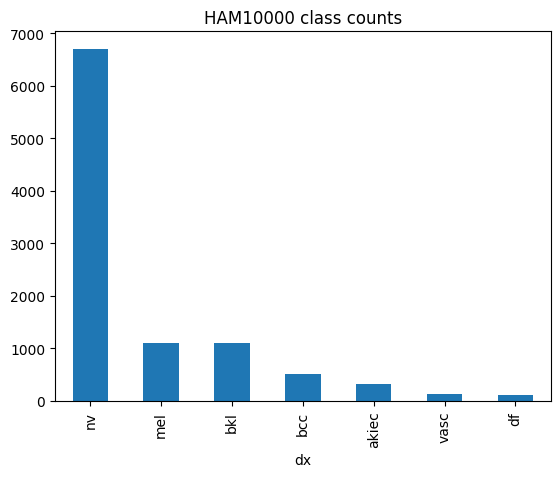

In [5]:
counts = meta['dx'].value_counts()
print(counts)
counts.plot(kind='bar', title='HAM10000 class counts')

In [6]:
from sklearn.model_selection import train_test_split

lesions = meta.drop_duplicates('lesion_id')[['lesion_id', 'dx']]

train_l, temp_l = train_test_split(lesions, test_size=0.30,
                                   stratify=lesions['dx'], random_state=42)
val_l, test_l = train_test_split(temp_l, test_size=0.50,
                                 stratify=temp_l['dx'], random_state=42)

train = meta[meta.lesion_id.isin(train_l.lesion_id)].copy()
val   = meta[meta.lesion_id.isin(val_l.lesion_id)].copy()
test  = meta[meta.lesion_id.isin(test_l.lesion_id)].copy()

print("Images:", len(train), len(val), len(test))

# leak check: all three must print 0
print(len(set(train.lesion_id) & set(val.lesion_id)))
print(len(set(train.lesion_id) & set(test.lesion_id)))
print(len(set(val.lesion_id) & set(test.lesion_id)))

# class counts per split
print(pd.DataFrame({'train': train.dx.value_counts(),
                    'val': val.dx.value_counts(),
                    'test': test.dx.value_counts()}))

Images: 7002 1532 1481
0
0
0
       train   val  test
dx                      
akiec    230    51    46
bcc      366    77    71
bkl      774   157   168
df        76    19    20
mel      778   170   165
nv      4679  1034   992
vasc      99    24    19


In [7]:
for name, df in [('train', train), ('val', val), ('test', test)]:
    df.to_csv(f'{WORK}/{name}.csv', index=False)
print(os.listdir(WORK))

['train.csv', 'val.csv', 'test.csv']


In [8]:
import pandas as pd
tr = pd.read_csv(f'{WORK}/train.csv'); va = pd.read_csv(f'{WORK}/val.csv'); te = pd.read_csv(f'{WORK}/test.csv')

print("Images:", len(tr), len(va), len(te), "| total:", len(tr)+len(va)+len(te))
print("Leaks (must be 0):",
      len(set(tr.lesion_id) & set(va.lesion_id)),
      len(set(tr.lesion_id) & set(te.lesion_id)),
      len(set(va.lesion_id) & set(te.lesion_id)))
print(pd.DataFrame({'train': tr.dx.value_counts(), 'val': va.dx.value_counts(), 'test': te.dx.value_counts()}))

Images: 7002 1532 1481 | total: 10015
Leaks (must be 0): 0 0 0
       train   val  test
dx                      
akiec    230    51    46
bcc      366    77    71
bkl      774   157   168
df        76    19    20
mel      778   170   165
nv      4679  1034   992
vasc      99    24    19
